In [8]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [9]:
from datetime import datetime, timedelta

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
papel = 'VALE3.SA'

In [12]:
# Parâmetros
DIAS_JANELA_X = 30  # janela de dados recentes que formam cada X
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [13]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base.tail(10)

[VALE3.SA] Cache existente cobre de 2020-01-02 a 2025-06-06.
[VALE3.SA] Cache cobre período solicitado (2022-12-18 a 2025-06-05).
[VALE3.SA] Retornando 614 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211218_20250606.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-06.
[^BVSP] Cache cobre período solicitado (2022-12-18 a 2025-06-05).
[^BVSP] Retornando 614 linhas para o período solicitado.


,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,...,atr_pct,tr_pct,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,
2025-05-23,54.000000,54.439999,53.590000,54.320000,14747300,0.001660,0.011485,50.058963,0.198339,0.120665,...,0.018621,0.015648,14.75,0.43,5.6932,137273.0,137824.0,134997.0,137824.0,10682600
2025-05-26,53.939999,54.090000,53.799999,54.009998,7194500,-0.005707,0.008531,47.730217,0.143336,0.125200,...,0.018077,0.009628,14.75,0.43,5.6619,137824.0,138800.0,137795.0,138136.0,5553800
2025-05-27,54.000000,54.209999,53.619999,53.840000,17943000,-0.003148,0.006143,46.453989,0.085048,0.117169,...,0.017622,0.010958,14.75,0.43,5.6539,138136.0,140382.0,138136.0,139541.0,11187800
2025-05-28,53.740002,53.790001,53.189999,53.410000,17700600,-0.007987,0.006356,43.300188,0.004110,0.094557,...,0.017364,0.012170,14.75,0.43,5.6936,139541.0,139547.0,138580.0,138888.0,9735000
2025-05-29,53.730000,53.880001,53.330002,53.450001,10246100,0.000749,0.004768,43.683220,-0.056159,0.064414,...,0.016847,0.010290,14.75,0.43,5.6559,138869.0,139108.0,137993.0,138534.0,8826400
2025-05-30,53.349998,53.389999,52.049999,52.099998,28286100,-0.025257,0.008059,35.072027,-0.210431,0.009445,...,0.017968,0.026871,14.75,0.43,5.7087,138546.0,138637.0,136726.0,137027.0,15141600
2025-06-02,52.580002,52.750000,52.259998,52.560001,19267700,0.008829,0.009346,39.451885,-0.292206,-0.050885,...,0.017422,0.012367,14.75,0.43,5.6937,137026.0,138471.0,136483.0,136787.0,9100100
2025-06-03,51.930000,52.639999,51.869999,52.529999,12824900,-0.000571,0.009302,39.265837,-0.355338,-0.111776,...,0.017234,0.014658,14.75,0.43,5.6694,136787.0,137672.0,136175.0,137546.0,9696700
2025-06-04,52.619999,53.330002,52.619999,52.770000,11714700,0.004569,0.009338,41.636867,-0.381606,-0.165742,...,0.017013,0.015160,14.75,0.43,5.6332,137547.0,138797.0,136695.0,137002.0,10199100


## Verificação da volatilidade recente

In [14]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-05-23,1.011466,0.018621,0.849998,0.015648
2025-05-26,0.976361,0.018077,0.520000,0.009628
2025-05-27,0.948764,0.017622,0.590000,0.010958
2025-05-28,0.927424,0.017364,0.650002,0.012170
2025-05-29,0.900465,0.016847,0.549999,0.010290
2025-05-30,0.936146,0.017968,1.400002,0.026871
2025-06-02,0.915707,0.017422,0.650002,0.012367
2025-06-03,0.905300,0.017234,0.770000,0.014658
2025-06-04,0.897778,0.017013,0.800003,0.015160


In [15]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 1.70%
Valorização sugerida: 2.54%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [16]:
valorizacao = 0.03
DIAS_FUTURO = 8  # dias futuros para buscar a valorização

In [17]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)
df['Target'].value_counts(normalize=True)

Target
0.0    0.653465
1.0    0.346535
Name: proportion, dtype: float64

In [18]:
# Preparar X e y para treino
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

In [19]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=3,
                                        min_samples_leaf=50,
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'

                                        )
modelo.fit(X_train.values, y_train.values)

from sklearn.metrics import roc_auc_score
roc = roc_auc_score(y_train, modelo.predict_proba(X_train.values)[:,1])
print(f"AUC no treino: {roc:.3f}")
roc_validacao = roc_auc_score(y_validacao, modelo.predict_proba(X_validacao.values)[:,1])
print(f"AUC na validação: {roc_validacao:.3f}")


AUC no treino: 0.881
AUC na validação: 0.592


Avaliar e logar modelo
MLflow Run ID: f2d5e9c261e541d2bcb0244e757d7e2a para VALE3.SA_30dias_x_0.03val_8dias_alvo
AUC no treino: 0.881
AUC na validação: 0.592

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.68
  Precisão Média Esperada: 100.00%
  Recall Médio Esperado: 12.75%
  Janelas Usadas para Precisão: 154.0

Threshold ideal baseado em recall mínimo: 0.68

--- Conjunto de Validação --- Janelas
Precisão média (em 9 janelas com previsão positiva): 0.617
Recall médio: 0.015
Sinais de compra presentes na vallidação: 40.0
Sinais de compra previstos na validação: 7
Modelo VALE3.SA_30dias_x_0.03val_8dias_alvo salvo na run f2d5e9c261e541d2bcb0244e757d7e2a


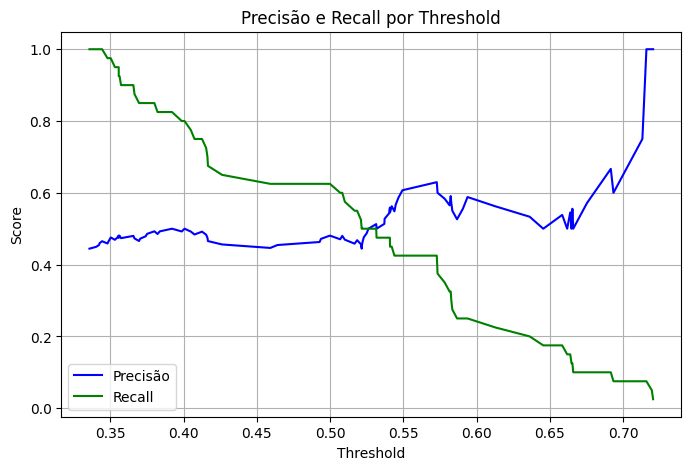

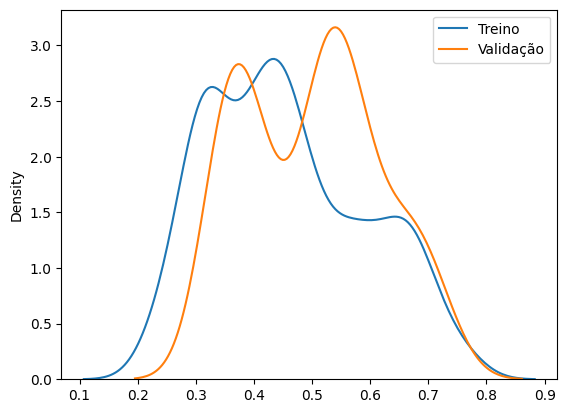

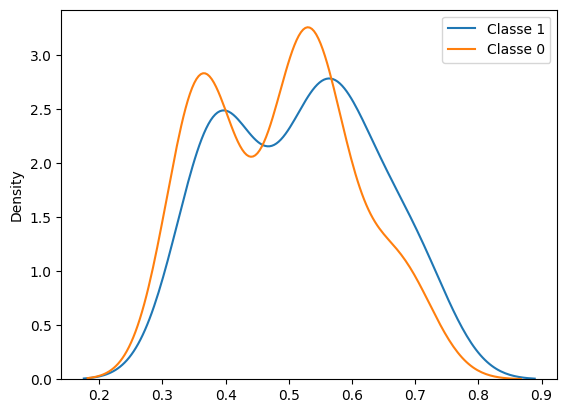

In [ ]:
recall_minimo = 0.1  # mínimo de recall desejado
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [21]:
from sklearn.calibration import CalibratedClassifierCV


calibrated_model = CalibratedClassifierCV(modelo, method='sigmoid', cv=5)
calibrated_model.fit(X_train.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(class_weight='balanced',
                                                        max_depth=3,
                                                        max_features=0.2,
                                                        min_samples_leaf=50,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42))

In [22]:
recall_minimo = 0.1  # mínimo de recall desejado
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)


Avaliar e logar modelo
MLflow Run ID: 720efb20394e45c7b0ed10a6611e8a52 para VALE3.SA_30dias_x_0.03val_8dias_alvo
AUC no treino: 0.703
AUC na validação: 0.665

--- Conjunto de Treino --- Janelas
Nenhum threshold atendeu ao recall mínimo de 0.10.


TypeError: unsupported format string passed to NoneType.__format__

# Redução de features

## Eliminação por correlação

In [23]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['tr_mean', 'macd_hist_ultimo', 'close_mean', 'macd_ultimo', 'macd_signal_ultimo', 'macd_signal_mean', 'macd_conf_ultimo', 'close_std', 'retorno_acumulado', 'close_max', 'tr_pct_ultimo', 'macd_conf_mean', 'dias_alta_pct']


In [24]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


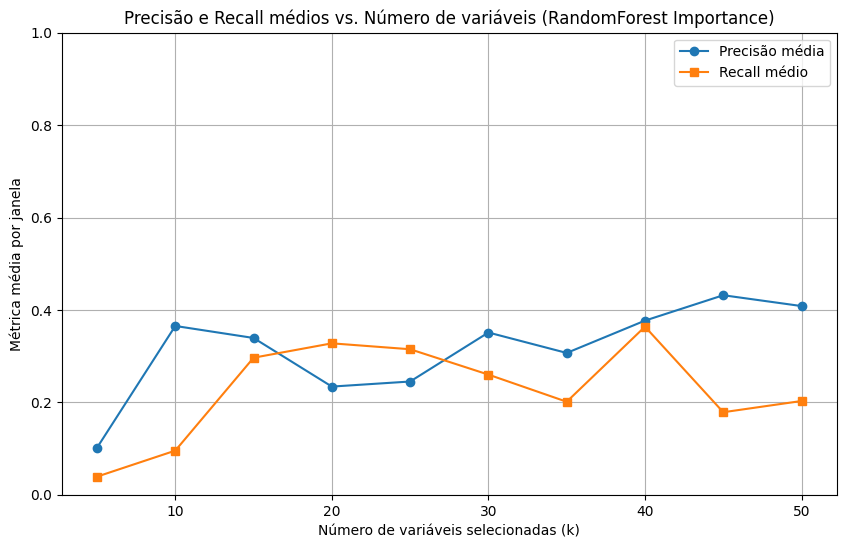

In [25]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [29]:
n_features = 20
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['ipca_ultimo',
 'tr_std',
 'tr_pct_std',
 'retorno_medio_neg',
 'volume_mean',
 'close_min',
 'close_amplitude_norm_atr',
 'retorno_std',
 'retorno_medio_pos',
 'atr_pct_mean',
 'ibov_amplitude',
 'close_mean',
 'volume_trend',
 'tr_std_norm_atr',
 'volume_std',
 'atr_ultimo',
 'close_amplitude',
 'macd_std',
 'close_trend',
 'macd_signal_ultimo']

In [30]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [31]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=5,
                                        #min_samples_split=50,
                                        min_samples_leaf=20,                                        
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.940
AUC na validação: 0.560
Diferença AUC (Treino - Validação): 0.380
PROVÁVEL OVERFITTING


In [34]:
calibrated_model = CalibratedClassifierCV(modelo_reduzido, method='sigmoid', cv=5)
calibrated_model.fit(X_train_reduzido.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(max_depth=5,
                                                        max_features=0.2,
                                                        min_samples_leaf=20,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42))

Avaliar e logar modelo
MLflow Run ID: 6b68fc40468345c1a37272a55a624e8a para VALE3.SA_30dias_x_0.03val_8dias_alvo
AUC no treino: 0.889
AUC na validação: 0.591

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.52
  Precisão Média Esperada: 94.25%
  Recall Médio Esperado: 30.36%
  Janelas Usadas para Precisão: 193.0

Threshold ideal baseado em recall mínimo: 0.52

--- Conjunto de Validação --- Janelas
Precisão média (em 15 janelas com previsão positiva): 0.211
Recall médio: 0.022
Sinais de compra presentes na vallidação: 40.0
Sinais de compra previstos na validação: 10
Modelo VALE3.SA_30dias_x_0.03val_8dias_alvo salvo na run 6b68fc40468345c1a37272a55a624e8a


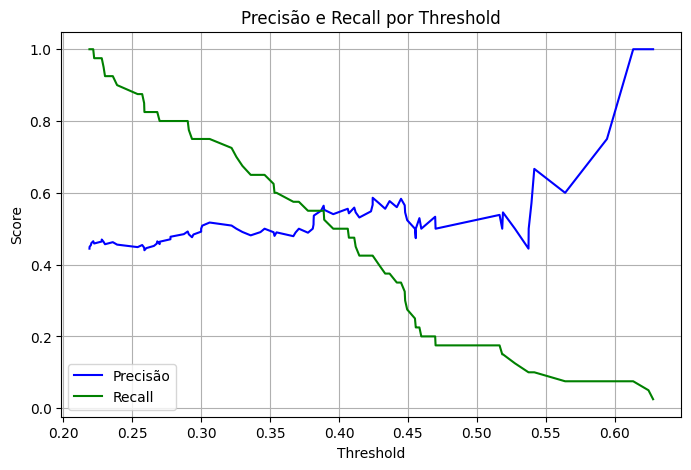

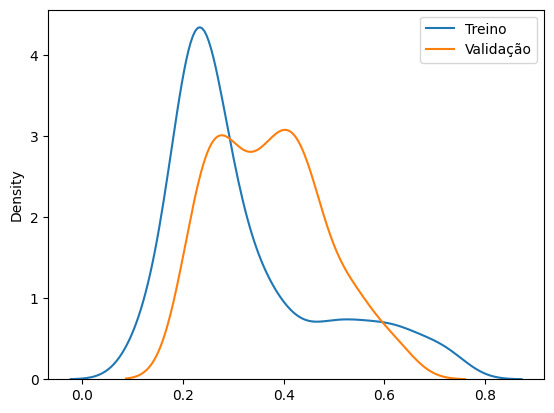

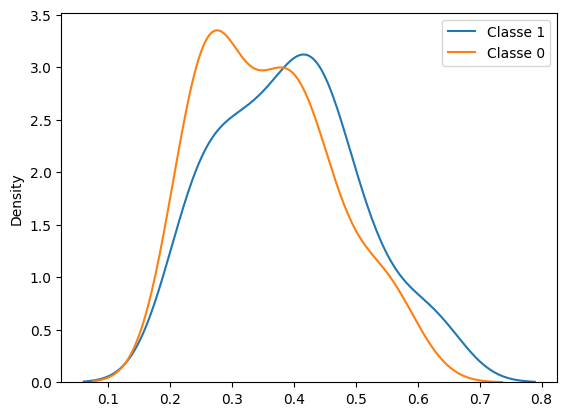

In [35]:
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.3)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

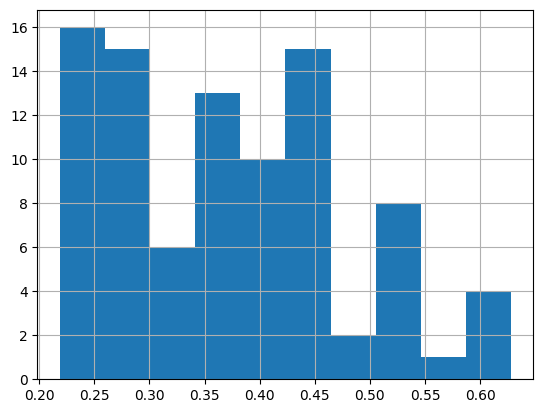

In [36]:
pd.Series(probas).hist()